# Does Look-Ahead Bias Fake Good Risk Forecasts?

**Research question:** How much does look-ahead bias inflate the apparent performance of machine-learning market regime models in Value-at-Risk forecasting?

This notebook runs the whole experiment on the S&P 500:

| Version | How it is built | Valid forecast? |
|---|---|---|
| **A. Honest** | Refit every 21 trading days on the last 1,000 days, filtered probabilities | Yes |
| **B. Future-trained** | Fit once on all data, filtered probabilities | No, deliberate bias test |
| **C. Retrospective** | Fit once on all data, smoothed probabilities | No, deliberate bias test |

Benchmarks: **historical simulation** (last 250 days) and **GARCH(1,1)-t**.

All the model code lives in `regime_var.py`. This notebook calls it, shows the results and draws the charts. Read `regime_var.py` too: you need to be able to explain every step in your paper.

**On Google Colab:** upload `regime_var.py` (and `data/sp500.csv` if you have it) using the folder icon on the left, then run the install cell below.

In [1]:
# Run this once on Google Colab (already installed if you use the project's .venv)
# !pip install hmmlearn arch yfinance

## 1. Settings (decided in advance, do not change after seeing results)

Changing these after looking at the results would be a form of look-ahead bias too. If you want to try other values, report them as robustness checks.

In [2]:
import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import regime_var as rv

warnings.filterwarnings("ignore")
pd.set_option("display.precision", 4)

TICKER = "^GSPC"                 # S&P 500
FORECAST_START = "2005-01-03"    # first day we forecast
ALPHAS = (0.05, 0.01)            # 95% and 99% VaR
WINDOW = 1000                    # Version A: days of past data used for each refit
REFIT_EVERY = 21                 # Version A: refit about once a month
N_REGIMES = 2                    # calm and stormy

CRISES = {
    "2008 crisis": ("2008-09-01", "2009-06-30"),
    "COVID 2020": ("2020-02-15", "2020-06-30"),
    "2022 sell-off": ("2022-01-01", "2022-12-31"),
}

os.makedirs("data", exist_ok=True)
os.makedirs("results", exist_ok=True)

## 2. Data

Daily S&P 500 closing prices from Yahoo Finance, turned into daily log returns in percent. The prices are saved to `data/sp500.csv` the first time, so later runs do not need the internet and everyone gets exactly the same data.

In [3]:
returns = rv.load_returns(TICKER, cache_path="data/sp500.csv")
print(f"{len(returns)} daily returns from {returns.index[0].date()} to {returns.index[-1].date()}")
returns.describe()

9066 daily returns from 1990-01-03 to 2025-12-31


count    9066.0000
mean        0.0325
std         1.1385
min       -12.7652
25%        -0.4437
50%         0.0600
75%         0.5694
max        10.9572
Name: return, dtype: float64

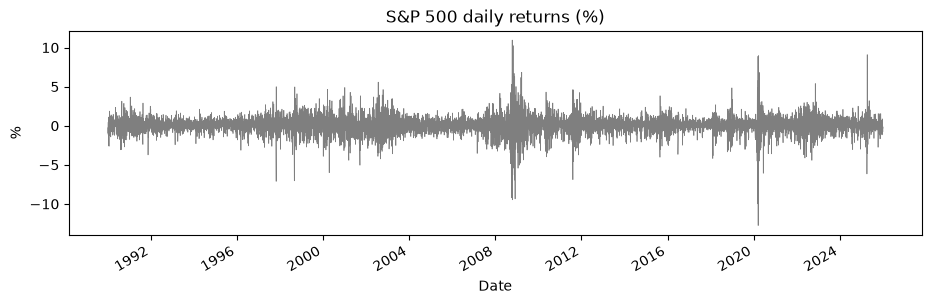

In [4]:
fig, ax = plt.subplots(figsize=(11, 3))
returns.plot(ax=ax, lw=0.5, color="tab:gray")
ax.set_title("S&P 500 daily returns (%)")
ax.set_ylabel("%")
plt.show()

## 3. What do the regimes look like?

Here we fit one HMM on **all** the data, only to look at it. The chart compares two ways of asking "how likely is it that today is stormy?":

- **Filtered**: uses data up to today only. This is what a real forecaster could know.
- **Smoothed**: uses the whole dataset, including the future. It looks cleaner because it cheats.

The gap between the two lines is the hindsight that Version C gets for free.

Regime means (%): [ 0.081 -0.084]
Regime daily volatility (%): [0.676 1.818]
Chance of staying in the same regime tomorrow: [0.987 0.969]


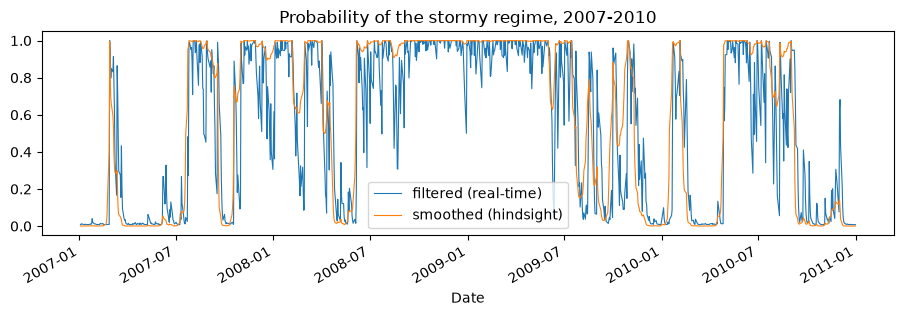

In [5]:
x = returns.to_numpy()
full_model = rv.fit_hmm(x, n_regimes=N_REGIMES)
means, sds, transmat, startprob = rv.hmm_params(full_model)

print("Regime means (%):", means.round(3))
print("Regime daily volatility (%):", sds.round(3))
print("Chance of staying in the same regime tomorrow:", np.diag(transmat).round(3))

stormy_filtered = pd.Series(rv.filtered_probs(x, means, sds, transmat, startprob)[:, 1], index=returns.index)
stormy_smoothed = pd.Series(full_model.predict_proba(x.reshape(-1, 1))[:, 1], index=returns.index)

fig, ax = plt.subplots(figsize=(11, 3))
stormy_filtered.loc["2007":"2010"].plot(ax=ax, lw=0.8, label="filtered (real-time)")
stormy_smoothed.loc["2007":"2010"].plot(ax=ax, lw=0.8, label="smoothed (hindsight)")
ax.set_title("Probability of the stormy regime, 2007-2010")
ax.legend()
plt.show()

## 4. Run all five methods

Version A refits the HMM about 250 times, so it takes roughly a minute. The others take a few seconds.

In [6]:
forecasts = {
    "A honest": rv.hmm_var_rolling(returns, FORECAST_START, ALPHAS, window=WINDOW, refit_every=REFIT_EVERY, n_regimes=N_REGIMES),
    "B future-trained": rv.hmm_var_full_sample(returns, FORECAST_START, ALPHAS, smoothed=False, n_regimes=N_REGIMES),
    "C retrospective": rv.hmm_var_full_sample(returns, FORECAST_START, ALPHAS, smoothed=True, n_regimes=N_REGIMES),
    "Historical sim": rv.historical_var(returns, FORECAST_START, ALPHAS),
    "GARCH-t": rv.garch_var(returns, FORECAST_START, ALPHAS, window=WINDOW, refit_every=REFIT_EVERY),
}
for name, frame in forecasts.items():
    print(f"{name:18s} {len(frame)} forecasts")

A honest           5283 forecasts
B future-trained   5283 forecasts
C retrospective    5283 forecasts
Historical sim     5283 forecasts
GARCH-t            5283 forecasts


## 5. Main results (2005-2025)

How to read the table:
- **breach rate %** should be close to the **target %**.
- **Kupiec p** and **Christoffersen p** above 0.05 mean the test does not reject the model.
- **quantile loss** is the main accuracy score. Lower is better.

In [7]:
results = rv.evaluate(returns, forecasts, ALPHAS)
results.to_csv("results/main_results.csv", index=False)
results

,method,VaR level,days,breach rate %,target %,Kupiec p,Christoffersen p,quantile loss
0,A honest,95%,5283,5.6975,5.0,2.2739e-02,3.6586e-02,0.1379
1,A honest,99%,5283,1.9496,1.0,8.3412e-10,4.2648e-10,0.0463
2,B future-trained,95%,5283,5.9625,5.0,1.8109e-03,7.5609e-03,0.1351
3,B future-trained,99%,5283,1.8171,1.0,8.4812e-08,7.0331e-08,0.0444
4,C retrospective,95%,5283,4.4861,5.0,8.1336e-02,1.2816e-01,0.1168
5,C retrospective,99%,5283,1.0032,1.0,9.8126e-01,7.9165e-03,0.0368
6,Historical sim,95%,5283,5.4893,5.0,1.0792e-01,2.4814e-07,0.1459
7,Historical sim,99%,5283,1.7793,1.0,2.9026e-07,1.2907e-08,0.0491
8,GARCH-t,95%,5283,6.7765,5.0,1.7613e-08,1.2786e-07,0.1256
9,GARCH-t,99%,5283,1.7793,1.0,2.9026e-07,5.7074e-07,0.0368


## 6. The headline number: the look-ahead premium

How much lower (better) is the quantile loss of the biased versions compared with the honest one? This percentage is the core result of the paper.

In [8]:
loss = results.pivot(index="method", columns="VaR level", values="quantile loss")
premium = pd.DataFrame({
    "B vs A (future-trained parameters) %": 100 * (loss.loc["A honest"] - loss.loc["B future-trained"]) / loss.loc["A honest"],
    "C vs A (total look-ahead) %": 100 * (loss.loc["A honest"] - loss.loc["C retrospective"]) / loss.loc["A honest"],
}).T
premium.to_csv("results/look_ahead_premium.csv")
premium.round(1)

VaR level,95%,99%
B vs A (future-trained parameters) %,2.1,4.2
C vs A (total look-ahead) %,15.3,20.5


## 7. Are the differences real? Diebold-Mariano tests

A negative statistic means the first model has lower loss. A p-value below 0.05 means the difference is unlikely to be luck.

In [9]:
pairs = [
    ("C retrospective", "A honest"),
    ("B future-trained", "A honest"),
    ("A honest", "Historical sim"),
    ("A honest", "GARCH-t"),
]
rows = []
for a in ALPHAS:
    col = f"q{int(round(100 * a))}"
    for first, second in pairs:
        idx = forecasts[first].index
        r = returns.loc[idx]
        loss_1 = rv.quantile_loss(r, forecasts[first][col], a)
        loss_2 = rv.quantile_loss(r, forecasts[second].loc[idx, col], a)
        stat, p = rv.diebold_mariano(loss_1, loss_2)
        rows.append({"VaR level": f"{int(round(100 * (1 - a)))}%", "comparison": f"{first} vs {second}", "DM statistic": stat, "p-value": p})
dm = pd.DataFrame(rows)
dm.to_csv("results/diebold_mariano.csv", index=False)
dm

,VaR level,comparison,DM statistic,p-value
0,95%,C retrospective vs A honest,-7.8405,4.4409e-15
1,95%,B future-trained vs A honest,-1.3037,1.9234e-01
2,95%,A honest vs Historical sim,-2.8552,4.3013e-03
3,95%,A honest vs GARCH-t,2.7560,5.8509e-03
4,99%,C retrospective vs A honest,-4.7691,1.8503e-06
5,99%,B future-trained vs A honest,-1.0854,2.7775e-01
6,99%,A honest vs Historical sim,-1.2258,2.2027e-01
7,99%,A honest vs GARCH-t,1.9976,4.5755e-02


## 8. Crisis vs calm periods

Does the look-ahead premium get bigger during crises? Hindsight helps most when regimes switch.

In [10]:
in_crisis = pd.Series(False, index=returns.index)
for start, end in CRISES.values():
    in_crisis.loc[start:end] = True

def subset_results(mask):
    subset = {name: frame.loc[mask.reindex(frame.index)] for name, frame in forecasts.items()}
    return rv.evaluate(returns, subset, ALPHAS)

crisis = subset_results(in_crisis).assign(period="crisis")
calm = subset_results(~in_crisis).assign(period="calm")
by_period = pd.concat([crisis, calm])
by_period.to_csv("results/crisis_vs_calm.csv", index=False)
by_period.pivot_table(index="method", columns=["period", "VaR level"], values="quantile loss")

period              calm          crisis        
VaR level            95%     99%     95%     99%
method                                          
A honest          0.1110  0.0331  0.3674  0.1589
B future-trained  0.1105  0.0323  0.3443  0.1475
C retrospective   0.0917  0.0246  0.3312  0.1417
GARCH-t           0.1077  0.0322  0.2784  0.0767
Historical sim    0.1192  0.0381  0.3740  0.1433

## 9. Charts for the paper

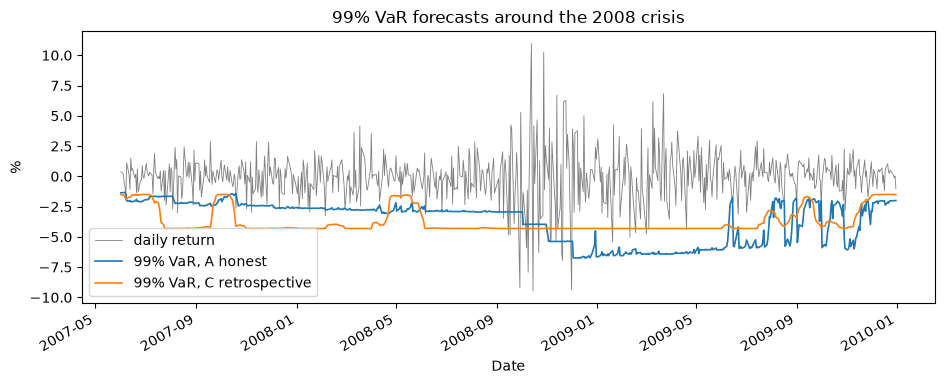

In [11]:
r = returns.loc[forecasts["A honest"].index]
fig, ax = plt.subplots(figsize=(11, 4))
window = slice("2007-06-01", "2009-12-31")
r.loc[window].plot(ax=ax, lw=0.6, color="tab:gray", label="daily return")
forecasts["A honest"].loc[window, "q1"].plot(ax=ax, lw=1.2, label="99% VaR, A honest")
forecasts["C retrospective"].loc[window, "q1"].plot(ax=ax, lw=1.2, label="99% VaR, C retrospective")
ax.set_title("99% VaR forecasts around the 2008 crisis")
ax.set_ylabel("%")
ax.legend(loc="lower left")
fig.savefig("results/var_lines_2008.png", dpi=200, bbox_inches="tight")
plt.show()

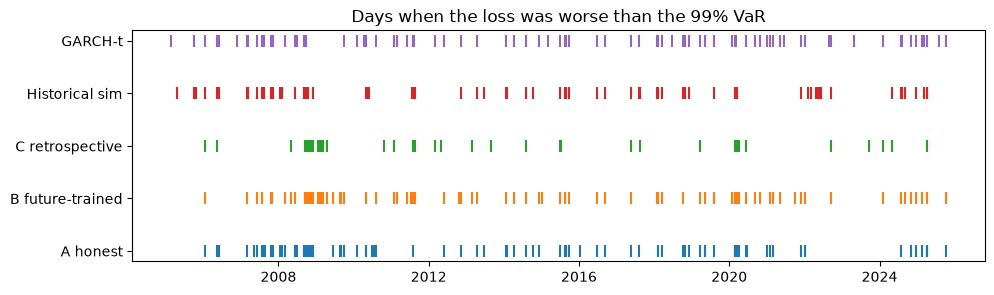

In [12]:
fig, ax = plt.subplots(figsize=(11, 3))
names = list(forecasts)
for i, name in enumerate(names):
    frame = forecasts[name]
    hits = rv.breaches(returns.loc[frame.index], frame["q1"]).astype(bool)
    ax.scatter(frame.index[hits], np.full(hits.sum(), i), marker="|", s=80)
ax.set_yticks(range(len(names)))
ax.set_yticklabels(names)
ax.set_title("Days when the loss was worse than the 99% VaR")
fig.savefig("results/breach_timeline.png", dpi=200, bbox_inches="tight")
plt.show()

## 10. What to do next

1. **Check the sanity order.** C should have the lowest loss and A the highest of the three HMM versions. If not, find out why before writing.
2. **Interpret.** How big is the premium? Does the honest HMM beat historical simulation and GARCH? Is the premium bigger in crises?
3. **Run the tests** in `tests/` (`python -m pytest`). They prove that Version A never uses future data.
4. **Only if there is time:** set `TICKER = "^FTSE"` (and a new `cache_path`) to repeat the study on a second index.

Every table and chart is saved in `results/`, ready for the paper.